First 5 rows of Housing Dataset:
   Size  Bedrooms     Price
0  7420         4  13300000
1  8960         4  12250000
2  9960         3  12250000
3  7500         4  12215000
4  7420         4  11410000


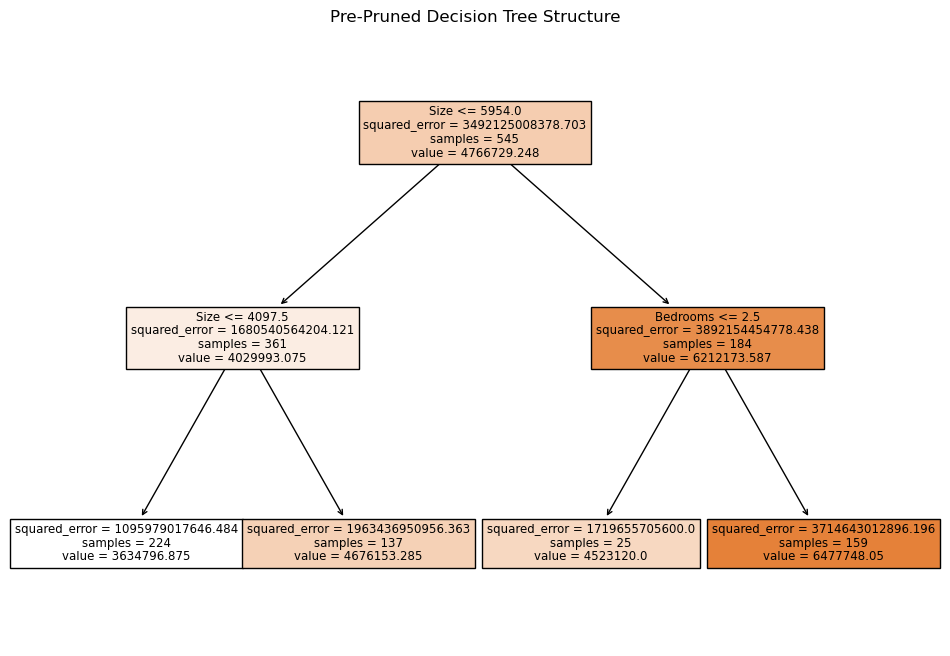


Predicted Price for 2500 sq.ft, 3-bedroom house: $3,634,796.88

--- No Pruning Tree ---
MSE: 503601359513.3727
R² Score: 0.8557894238307404

--- Post-Pruned Tree ---
MSE: 550065367158.9381
R² Score: 0.842484056029163


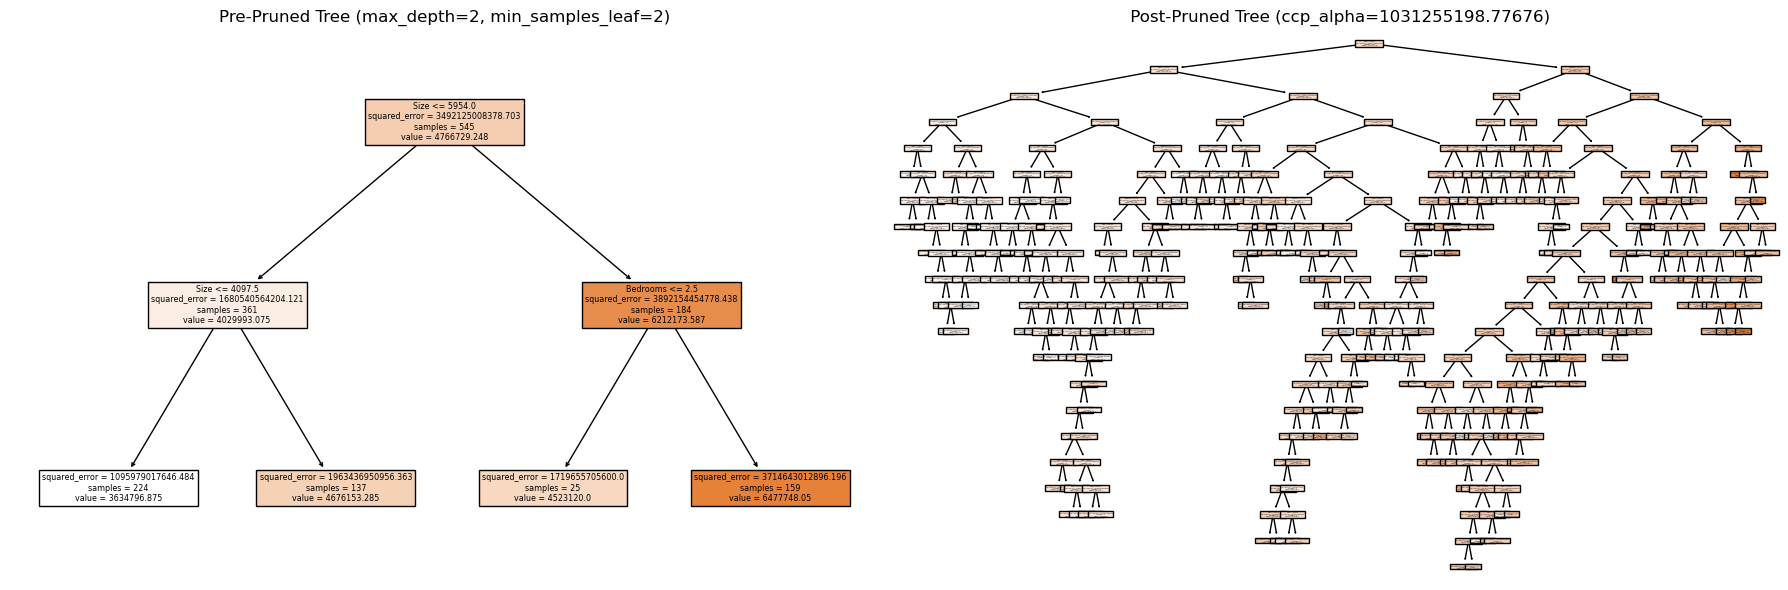


Predicted Prices for [2000 sq.ft, 3 bedrooms]:
No Pruning Tree: $3,850,000.00
Post-Pruned Tree: $3,614,654.17


In [8]:
# Import Required Libraries
import pandas as pd
import numpy as np
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# ---------------------------------
# Load and Inspect Dataset
# ---------------------------------
# Load dataset from Housing.csv
df = pd.read_csv('Housing.csv')

# Rename columns to match the lab manual naming convention
df = df.rename(columns={'area': 'Size', 'bedrooms': 'Bedrooms', 'price': 'Price'})

# Print the first 5 rows
print("First 5 rows of Housing Dataset:")
print(df[['Size', 'Bedrooms', 'Price']].head())

# ---------------------------------
# Split Features and Target
# ---------------------------------
X = df[['Size', 'Bedrooms']]
y = df['Price']

# ---------------------------------
# Train Decision Tree Regressor (Pre-Pruned)
# ---------------------------------
# Create model object (Pre-pruned with max_depth=2, min_samples_leaf=2)
reg_pre = DecisionTreeRegressor(max_depth=2, min_samples_leaf=2, random_state=0)

# Train the model
reg_pre.fit(X, y)

# Visualize the Decision Tree
plt.figure(figsize=(12, 8))
plot_tree(reg_pre, filled=True, feature_names=["Size", "Bedrooms"])
plt.title("Pre-Pruned Decision Tree Structure")
plt.show()

# ---------------------------------
# Make Predictions
# ---------------------------------
# Predict price for a new house: 2500 sq.ft house with 3 bedrooms
new_data = pd.DataFrame([[2500, 3]], columns=['Size', 'Bedrooms'])
predicted_price = reg_pre.predict(new_data)
print(f"\nPredicted Price for 2500 sq.ft, 3-bedroom house: ${predicted_price[0]:,.2f}")

# ---------------------------------
# Post-Pruning (Cost Complexity Pruning)
# Grow full tree first, then prune using ccp_alpha
# ---------------------------------
reg_full = DecisionTreeRegressor(random_state=0)
reg_full.fit(X, y)

path = reg_full.cost_complexity_pruning_path(X, y)
ccp_alphas = path.ccp_alphas  # Array of possible pruning strengths

# Choose a middle alpha value
chosen_alpha = ccp_alphas[len(ccp_alphas) // 2]

reg_post = tree.DecisionTreeRegressor(random_state=0, ccp_alpha=chosen_alpha)
reg_post.fit(X, y)

# ---------------------------------
# Evaluate Model
# ---------------------------------
models = {
    "No Pruning Tree": reg_full,
    "Post-Pruned Tree": reg_post
}

for name, model in models.items():
    y_pred = model.predict(X)
    print(f"\n--- {name} ---")
    print("MSE:", mean_squared_error(y, y_pred))
    print("R² Score:", r2_score(y, y_pred))

# ---------------------------------
# Visual Comparison of Tree Structures
# ---------------------------------
plt.figure(figsize=(18, 6))

plt.subplot(121)
tree.plot_tree(reg_pre, filled=True, feature_names=["Size", "Bedrooms"])
plt.title("Pre-Pruned Tree (max_depth=2, min_samples_leaf=2)")

plt.subplot(122)
tree.plot_tree(reg_post, filled=True, feature_names=["Size", "Bedrooms"])
plt.title(f" Post-Pruned Tree (ccp_alpha={chosen_alpha:.5f})")

plt.tight_layout()
plt.show()

# ---------------------------------
# Predict a new sample for comparison
# ---------------------------------
new_house = pd.DataFrame([[2000, 3]], columns=['Size', 'Bedrooms'])

print("\nPredicted Prices for [2000 sq.ft, 3 bedrooms]:")
for name, model in models.items():
    print(f"{name}: ${model.predict(new_house)[0]:,.2f}")